## NBA Player Minutes Predictor - XGBoost Quantile
**- Owner:** Alex

**- Status:** Exploration only. One added feature at a time, scored against the saved 14-feature model.

**- Last Updated:** 10/25/26

**- Baseline:** Keep the bar 01 used. Quantile XGBoost saved at `models/saved_models/min_nba_model_2026-04-12.joblib`. Walk-forward q50 pinball 2.226. 2025-26 holdout q50 pinball 2.223, 80% coverage 79.6%, 90% coverage 89.7%. Do not promote 01's matchup features (`min_mean_vs_opp`, `games_vs_opp`). The 16-feature list that includes them scored walk-forward 2.231 and holdout 2.233 on the 2026-10-25 run.

### Question

**Does player team spread or game total lower walk-forward q50 pinball below 2.226?**

### Decision Criteria
**- Primary metric:** q50 pinball (minutes) on the walk-forward folds. Lower than 2.226 is better. Add one column in the play cell. Keep it only if removing it raises pinball.

**- Secondary metric:** 80% interval (q10–q90) and 90% interval (q05–q95) coverage near their targets

**- Serving threshold:** none yet — exploration only

**- Guardrail:** same hyperparameters as the saved model. No quantile crossing. 2025-26 is scored once, after the feature is locked, and is never used to tune.

### Data Contract
**- Data:** nba_api, rotowire, and basketball reference

**- Unit:** one row per player-game (`game_id`, `player_id`)

**- Label:** minutes played (`minutes` > 0)

**- Split:** chronological. Train 2019-10-22 → 2025-04-13. Validate inside that pool. Hold out 2025-10-21 → 2026-04-12.


### Setup and Configurations

The functions this notebook runs live in `notebooks/nba/minutes/src/minutes_xgb`. Import that package to start another minutes notebook.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_SRC = Path("src").resolve()
if not (ANALYSIS_SRC / "minutes_xgb").is_dir():
    ANALYSIS_SRC = Path.cwd() / "notebooks/nba/minutes/src"
if str(ANALYSIS_SRC) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SRC))

from minutes_xgb.paths import ensure_repo_on_path, repo_root

ensure_repo_on_path()

from minutes_xgb import (
    ARTIFACT_STEM,
    HOLDOUT_SEASON,
    ID_COLS,
    MIN_FEATURES,
    MIN_TIERS,
    QUANTILES,
    ROLE_COL,
    TARGET_COL,
    XGB_PARAMS,
    build_miss_frame,
    build_model_frame,
    build_oos_predictions,
    compare_to_baselines,
    data_quality,
    exploratory_metadata,
    feature_consensus,
    feature_missingness,
    feature_outlier_table,
    format_data_quality,
    format_minutes_outliers,
    holdout_point_distribution,
    interval_sharpness,
    load_regular_season,
    loaded_holdout_scores,
    mean_absolute_shap,
    minutes_outlier_summary,
    miss_view,
    missingness_summary,
    monotone_shift,
    permutation_importance_table,
    plot_minutes,
    plot_missingness,
    plot_shap,
    positive_minutes,
    predicted_minute_tiers,
    quantile_calibration,
    quantile_crossing,
    regular_season_blocks,
    role_quantile_fallback,
    role_reading,
    rotation_team_games,
    score_predictions,
    season_coverage,
    season_missingness,
    slice_score,
    tail_calibration_rows,
    top_minute_rows,
    write_oos_predictions,
)
from models.shared.analysis import analyze_correlations, run_feature_ablation
from models.shared.artifacts import load_model_bundle, save_model_bundle
from models.shared.splits import prepare_splits
from models.shared.train import evaluate_holdout, run_timeseries_cv, run_walk_forward

ROOT = repo_root()
pd.set_option("display.max_columns", None)


In [2]:
print(f"Holdout season: {HOLDOUT_SEASON}")
print(f"Config features ({len(MIN_FEATURES)}): {', '.join(MIN_FEATURES)}")
print(f"Quantiles: {QUANTILES}")


Holdout season: 2025-26
Config features (16): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home, min_mean_vs_opp, games_vs_opp
Quantiles: [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]


### Data

In [3]:
df = load_regular_season(ROOT)
df.sample(5)


,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,fga,fg_pct,fg3_m,fg3_a,fg3_pct,ftm,fta,ft_pct,oreb,dreb,reb,ast,tov,stl,blk,blka,pf,pfd,pts,plus_minus,nba_fantasy_pts,dd2,td3,wnba_fantasy_pts,fp_high_score,available_flag,min_sec,team_count,e_off_rating,off_rating,sp_work_off_rating,e_def_rating,def_rating,sp_work_def_rating,e_net_rating,net_rating,sp_work_net_rating,ast_pct,ast_to,ast_ratio,oreb_pct,dreb_pct,reb_pct,tm_tov_pct,e_tov_pct,efg_pct,ts_pct,usg_pct,e_usg_pct,e_pace,pace,pace_per40,sp_work_pace,pie,poss,fgm_pg,fga_pg,team_city,team_tricode,team_slug,first_name,family_name,name_i,player_slug,start_position,comment,jersey_num,minutes,spd,dist,orbc,drbc,rbc,tchs,sast,ftast,pass,assists,cfgm,cfga,cfg_pct,ufgm,ufga,uncontested_field_goals_percentage,field_goal_percentage,dfgm,dfga,dfg_pct,team_fgm,team_fga,team_fg_pct,team_fg3_m,team_fg3_a,team_fg3_pct,team_ftm,team_fta,team_ft_pct,team_oreb,team_dreb,team_reb,team_ast,team_tov,team_stl,team_blk,team_blka,team_pf,team_pfd,team_pts,team_plus_minus,team_e_off_rating,team_off_rating,team_e_def_rating,team_def_rating,team_e_net_rating,team_net_rating,team_ast_pct,team_ast_to,team_ast_ratio,team_oreb_pct,team_dreb_pct,team_reb_pct,team_tm_tov_pct,team_efg_pct,team_ts_pct,team_e_pace,team_pace,team_pace_per40,team_poss,team_pie,opp_team_id,opp_fgm,opp_fga,opp_fg_pct,opp_fg3_m,opp_fg3_a,opp_fg3_pct,opp_ftm,opp_fta,opp_ft_pct,opp_oreb,opp_dreb,opp_reb,opp_ast,opp_tov,opp_stl,opp_blk,opp_blka,opp_pf,opp_pfd,opp_pts,opp_plus_minus,opp_e_off_rating,opp_off_rating,opp_e_def_rating,opp_def_rating,opp_e_net_rating,opp_net_rating,opp_ast_pct,opp_ast_to,opp_ast_ratio,opp_oreb_pct,opp_dreb_pct,opp_reb_pct,opp_tm_tov_pct,opp_efg_pct,opp_ts_pct,opp_e_pace,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
151095,2025-26,201144,Mike Conley,Mike,1610612750,MIN,Minnesota Timberwolves,0022501152,2026-04-07T00:00:00,MIN @ IND,W,20.716667,3,6,0.500,2,4,0.5,0,0,0.0,2,0,2,3,3,3,0,0,3,1,8,15,20.9,0,0,21.0,25.0,1,20:43,1,111.0,117.8,117.8,86.4,84.4,84.4,24.5,33.3,33.3,0.176,1.0,25.0,0.087,0.000,0.054,25.0,25.0,0.667,0.667,0.158,0.161,106.26,104.26,86.89,104.26,0.071,45,3.0,6.0,Minnesota,MIN,timberwolves,Mike,Conley,M. Conley,mike-conley,G,,10,20.716667,4.62,1.59,2,2,4,47,1,0,42,3,1,2,0.5,2,4,0.500,0.500,1,1,1.0,46,89,0.517,17,41,0.415,15,16,0.938,10,29,39,27,20.0,16,4,1,22,16,124,20.0,116.9,119.2,99.4,101.0,17.5,18.3,0.587,1.35,18.5,0.341,0.780,0.553,0.192,0.612,0.646,105.3,103.5,86.25,104,0.571,1610612754,35,73,0.479,9,26,0.346,25,31,0.806,5,29,34,24,23.0,11,1,4,16,22,104,-20.0,99.4,101.0,116.9,119.2,-17.5,-18.3,0.686,1.04,17.8,0.220,0.659,0.447,0.223,0.541,0.600,105.3,103.5,86.25,103,0.429,Regular Season,PG,235.5,13.0,-13.0,1
170400,2025-26,1628398,Kyle Kuzma,Kyle,1610612749,MIL,Milwaukee Bucks,0022500297,2025-11-29T00:00:00,MIL vs. BKN,W,22.450000,3,5,0.600,1,1,1.0,4,4,1.0,0,1,1,3,1,3,0,1,2,2,11,6,24.7,0,0,22.0,27.0,1,22:27,1,131.0,126.7,126.7,109.3,110.9,110.9,21.6,15.8,15.8,0.176,3.0,27.3,0.000,0.048,0.025,9.1,9.3,0.700,0.814,0.160,0.163,96.38,97.28,81.07,97.28,0.119,45,3.0,5.0,Milwaukee,MIL,bucks,Kyle,Kuzma,K. Kuzma,kyle-kuzma,,,18,22.450000,4.30,1.61,1,3,4,30,0,0,27,3,1,1,1.0,2,4,0.500,0.600,3,3,1.0,44,84,0.524,16,39,0.410,12,17,0.706,12,31,43,31,14.0,13,2,4,16,16,116,17.0,124.1,123.4,100.5,106.5,23.6,17.0,0.705,2.21,22.3,0.349,0.705,0.529,0.149,0.619,0.634,96.0,93.5,77.92,94,0.628,1610612751,36,77,0.468,16,42,0.381,11,17,0.647,6,25,31,23,20.0,4,4,2,16,16,99,-17.0,100.5,106.5,124.1,123.4,-23.6,-17.0,0.639,1.15,17.8,0.295,0.651,0.471,0.215,0.571,0.586,96.0,93.5,77.92,93,0.372,Regular Season,PF,218.5,-11.5,-11.5,0
176146,2025-26,1642843,Cooper Flagg,Cooper,1610612742,DAL,Dallas Mavericks,0022500096,2025-10-24T00:00:00,DAL vs. WAS,L,34.656667,6,14,0.429,2,5,0.4,4,4,1.0,1,4,5,6,5,1,1,0,3,7,18,-6,34.0,0,0,35.0,41.0,1,34:39,1,94.8,93.9,93.9,103.7,101.2,101.2,-8.9,-7.3,-7.3,0.

In [4]:
print(format_data_quality(data_quality(df)))

Number of rows : 176738
Number of columns: 190
Number of Unique Players: 1172
Number of Unique Games: 8289
Total number of duplicates: 0
Missing Labels: 0
Missing Start Position: 0
Median Minutes: 23.64
Mean Minutes: 22.65
Max Minutes: 56.517
Standard Deviation of Minutes: 10.67
Skewness of Minutes: -0.279
Kurtosis of Minutes: -0.805
Percentage of players averaging 10+ minutes: 75.1%
Percentage of players averaging 20+ minutes: 34.9%
Percentage of players averaging 30+ minutes: 8.4%
Percentage of players averaging 35+ minutes: 0.9%


### Features

In [5]:
df = build_model_frame(df)
df['position_encoded'] = df['pos'].map({'PG': 1, 'SG': 2, 'SF': 3, 'PF': 4, 'C': 5})

In [6]:
import minutes_xgb.config as minutes_config

# Saved 14-feature model. 01's matchup columns stay off unless listed below.
PARKED_FEATURES = ("min_mean_vs_opp", "games_vs_opp")
LOCKED_FEATURES = [
    name for name in minutes_config.MIN_FEATURES if name not in PARKED_FEATURES
]
if len(LOCKED_FEATURES) != 14:
    raise RuntimeError(
        f"expected the saved 14-feature list, got {len(LOCKED_FEATURES)}: "
        f"{LOCKED_FEATURES}"
    )

# One column at a time. Both are already on the frame from the pregame line.
PLAY_FEATURES = [
    "player_team_spread",
    "min_mean_vs_opp",
    "games_vs_opp"
]
missing = [name for name in PLAY_FEATURES if name not in df.columns]
if missing:
    raise KeyError(f"play features are not on the frame: {missing}")
overlap = sorted(set(PLAY_FEATURES) & set(LOCKED_FEATURES))
if overlap:
    raise ValueError(f"play features already in the locked list: {overlap}")
if len(PLAY_FEATURES) != len(set(PLAY_FEATURES)):
    raise ValueError(f"duplicate play features: {PLAY_FEATURES}")

MIN_FEATURES = [*LOCKED_FEATURES, *PLAY_FEATURES]
print(f"Locked ({len(LOCKED_FEATURES)}): {', '.join(LOCKED_FEATURES)}")
print(f"Playing: {', '.join(PLAY_FEATURES) if PLAY_FEATURES else '(none)'}")
print(f"This run ({len(MIN_FEATURES)}): {', '.join(MIN_FEATURES)}")

Locked (14): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home
Playing: player_team_spread, min_mean_vs_opp, games_vs_opp
This run (17): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home, player_team_spread, min_mean_vs_opp, games_vs_opp


In [7]:
print(df["total_stars_active"].value_counts().sort_index())


total_stars_active
0       482
1      4279
2     32061
3    139916
Name: count, dtype: int64


In [8]:
print(f"Number of features: {len(MIN_FEATURES)}")
print(f"Number of nulls: {df[MIN_FEATURES].isna().sum().sum()}")


Number of features: 17
Number of nulls: 62138


### Train/validation/test design
**- Train:** 2019-10-22 → 2025-04-13. The printed walk-forward uses five date blocks, each the next 10% of train-pool dates after a 50% date window, stepping forward 10%. The scored windows are 2022-11-02 → 2023-02-07, 2023-02-07 → 2023-12-05, 2023-12-05 → 2024-03-17, 2024-03-17 → 2025-01-02, and 2025-01-02 → 2025-04-11. Dates before 2022-11-02 are train-only.

**- Validation:** `XGB_PARAMS` are the saved model's hyperparameters. `tune_xgb_quantile` is not run in this notebook. The TimeSeriesSplit cell uses the default five row folds and early-stops on the rows it scores. Walk-forward does not: `run_walk_forward` defaults to `early_stop="train_tail"`, so each fold stops on the last 10% of its training dates and scores the next date block.

**- Test:** 2025-10-21 → 2026-04-12 (2025-26). The holdout fit early-stops on the last 10% of train-pool rows (`iloc`), so the boundary date can be split, and never puts 2025-26 in `eval_set`. These outputs have been read. A later feature or pipeline change makes 2025-26 a development set, not a new blind test.

**- Split type:** Walk-forward keeps every row from a `game_date` on one side. TimeSeriesSplit and the holdout early-stopping cut are by row position.

**- Embargo:** None. The next game date after the last training date is validation. The gap from 2025-04-13 to 2025-10-21 is the offseason, not a purge.

**- Rows:** 176,738 raw rows. Feature construction replaces `minutes` with parsed `min_sec`. `minutes > 0` then leaves 176,710 rows. The 28 dropped rows are a `0:00` clock: 13 exact zeros, plus 15 stints under one second. There is no Tukey drop. The EDA fence [-9.27, 55.59] flags 4 rows and keeps them.

**- Label:** minutes on rows with a positive parsed clock. Zero-minute rows are excluded. The `✓ acceptable` flag is `abs(holdout pinball − walk-forward pinball) <= 0.25`. The 11-knot number printed as CRPS is twice the unweighted mean pinball at the trained knots, which are not equally spaced. Permutation importance uses `pinball_50`, which returns negative pinball, so a positive importance means the shuffle hurt.

In [9]:
df = positive_minutes(df)
print(f"After filtering minutes: {len(df):,} rows")

splits = prepare_splits(
    df,
    holdout_season=HOLDOUT_SEASON,
    features=MIN_FEATURES,
    target_col=TARGET_COL,
    id_cols=ID_COLS,
    role_col=ROLE_COL,
    extra_keep=["minutes", "pts", "min_ewm_hl_10"],
)
ppm_df = splits["ppm_df"]
ppm_holdout = splits["ppm_holdout"]
X = splits["X"]
y = splits["y"]


After filtering minutes: 176,710 rows
Train pool (excl. 2025-26) : 150,062 rows
Holdout   (2025-26)        : 26,648 rows
Date range (train)   : 2019-10-22 → 2025-04-13
Date range (holdout) : 2025-10-21 → 2026-04-12


### EDA

Appearance rows: 176,710
Features with a null: 11 / 17
Rows with any null feature: 34,611 (19.6%)


,n_missing,pct_missing
min_mean_vs_opp,26970,15.26
min_avg_lN,5944,3.36
min_p80_10,5629,3.19
min_p80_minus_p20_10,5629,3.19
player_team_spread,4197,2.38
player_days_since_appearance,3936,2.23
season_start_rate,3934,2.23
starter_min_missing_teammates,2360,1.34
start_rate_10,1172,0.66
min_lag_1,1172,0.66


,min_mean_vs_opp,min_avg_lN,min_p80_10,min_p80_minus_p20_10,player_team_spread,player_days_since_appearance,season_start_rate,starter_min_missing_teammates,start_rate_10,min_lag_1,min_ewm_hl_10
season_year,,,,,,,,,,,
2019-20,51.0,3.5,11.5,11.5,7.7,2.4,2.4,1.4,2.4,2.4,2.4
2020-21,15.6,3.4,2.3,2.3,0.0,2.3,2.3,1.4,0.5,0.5,0.5
2021-22,10.4,3.4,2.3,2.3,2.3,2.3,2.3,1.3,0.5,0.5,0.5
2022-23,7.6,3.2,1.6,1.6,0.7,2.1,2.1,1.3,0.3,0.3,0.3
2023-24,8.7,3.4,1.8,1.8,3.9,2.2,2.2,1.3,0.4,0.4,0.4
2024-25,9.3,3.4,2.0,2.0,0.2,2.2,2.2,1.4,0.4,0.4,0.4
2025-26,9.5,3.3,1.9,1.9,2.3,2.2,2.2,1.3,0.4,0.4,0.4


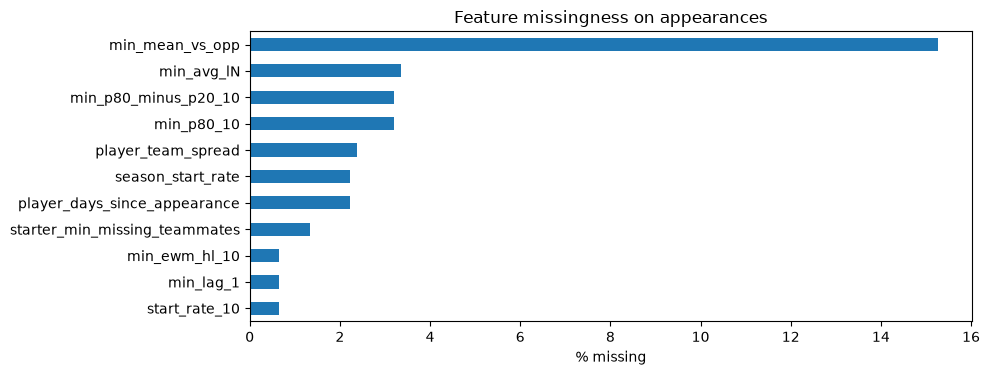

In [10]:
miss = feature_missingness(df, MIN_FEATURES)
print(missingness_summary(df, MIN_FEATURES))
display(miss)
season_miss = season_missingness(df, miss)
if season_miss.empty:
    print("Every selected feature is complete on this frame.")
else:
    display(season_miss)
    plot_missingness(miss)
    plt.show()


n=176,710  min=0.02  p50=23.65  max=56.52
Tukey fence [-9.27, 55.59]  outside=4 (0.0%)
Player minutes above 48 (overtime range): 81


,season_year,game_date,player_name,minutes,starting
62209,2021-22,2022-01-29,Pascal Siakam,56.516667,1
141903,2021-22,2022-01-29,Scottie Barnes,56.333333,1
71545,2021-22,2022-01-29,OG Anunoby,55.816667,1
92124,2021-22,2022-01-29,Gary Trent Jr.,55.650000,1
126602,2022-23,2023-03-05,Immanuel Quickley,55.100000,1
123639,2023-24,2024-04-07,Tyrese Maxey,53.950000,1
64751,2021-22,2022-01-29,Fred VanVleet,53.516667,1
155436,2024-25,2025-04-01,Christian Braun,53.166667,1


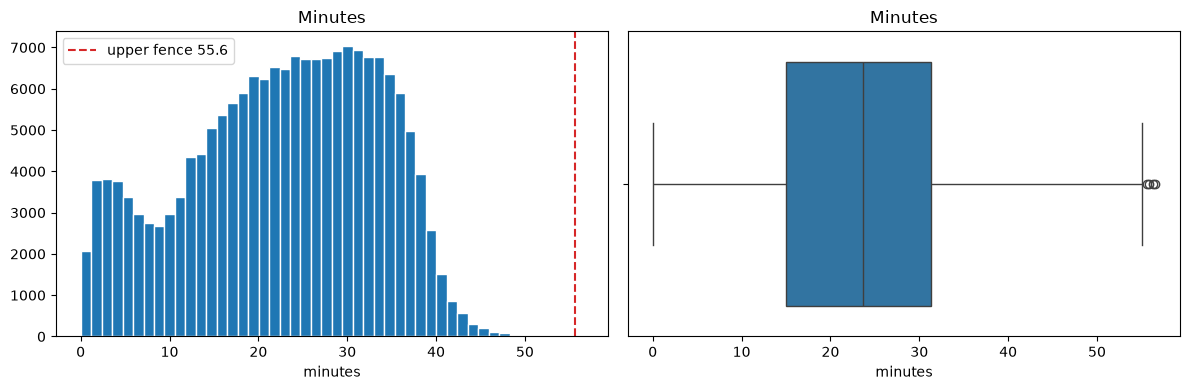

Binary inputs are omitted. A point is outside when it is past 1.5 IQR from the quartiles.


,feature,n,pct_outside,fence_low,fence_high,min,p50,max
0,player_days_since_appearance,172774,10.05,0.50,4.50,1.00,2.00,30.00
1,player_appearances_prev_7d,176710,7.79,0.50,4.50,0.00,3.00,5.00
2,min_p80_minus_p20_10,171081,3.09,-1.84,17.60,0.32,7.58,38.59
3,starter_min_missing_teammates,174350,2.01,-47.19,78.65,0.00,0.00,177.64
4,games_vs_opp,176710,1.93,-8.00,16.00,0.00,4.00,26.00
5,player_team_spread,172513,0.04,-23.25,22.75,-25.50,-1.00,25.50
6,starter_rank,176710,0.00,-7.50,20.50,1.00,7.00,22.00
7,start_rate_10,175538,0.00,-1.50,2.50,0.00,0.30,1.00
8,season_start_rate,172776,0.00,-1.50,2.50,0.00,0.28,1.00
9,min_avg_lN,170766,0.00,-6.06,51.99,0.00,23.37,48.89


In [11]:
outlier_stats = minutes_outlier_summary(df)
print(format_minutes_outliers(outlier_stats))
display(top_minute_rows(df))
plot_minutes(df, float(outlier_stats["fence_high"]))
plt.show()
print(
    "Binary inputs are omitted. A point is outside when it is past "
    "1.5 IQR from the quartiles."
)
display(feature_outlier_table(df, MIN_FEATURES))


In [12]:
coverage = season_coverage(df, MIN_FEATURES)
print(f"Seasons: {len(coverage)}  rows: {int(coverage['rows'].sum()):,}")
display(coverage)


Seasons: 7  rows: 176,710


,rows,players,games,first_game,last_game,pct_rows_complete,mean_missing_features
season_year,,,,,,,
2019-20,22387,529,1059,2019-10-22,2020-08-14,42.3,0.98
2020-21,23053,540,1080,2020-12-22,2021-05-16,81.8,0.31
2021-22,26035,605,1230,2021-10-19,2022-04-10,85.2,0.28
2022-23,25892,539,1230,2022-10-18,2023-04-09,89.3,0.21
2023-24,26393,572,1230,2023-10-24,2024-04-14,85.2,0.26
2024-25,26302,569,1230,2024-10-22,2025-04-13,87.9,0.24
2025-26,26648,582,1230,2025-10-21,2026-04-12,85.9,0.26


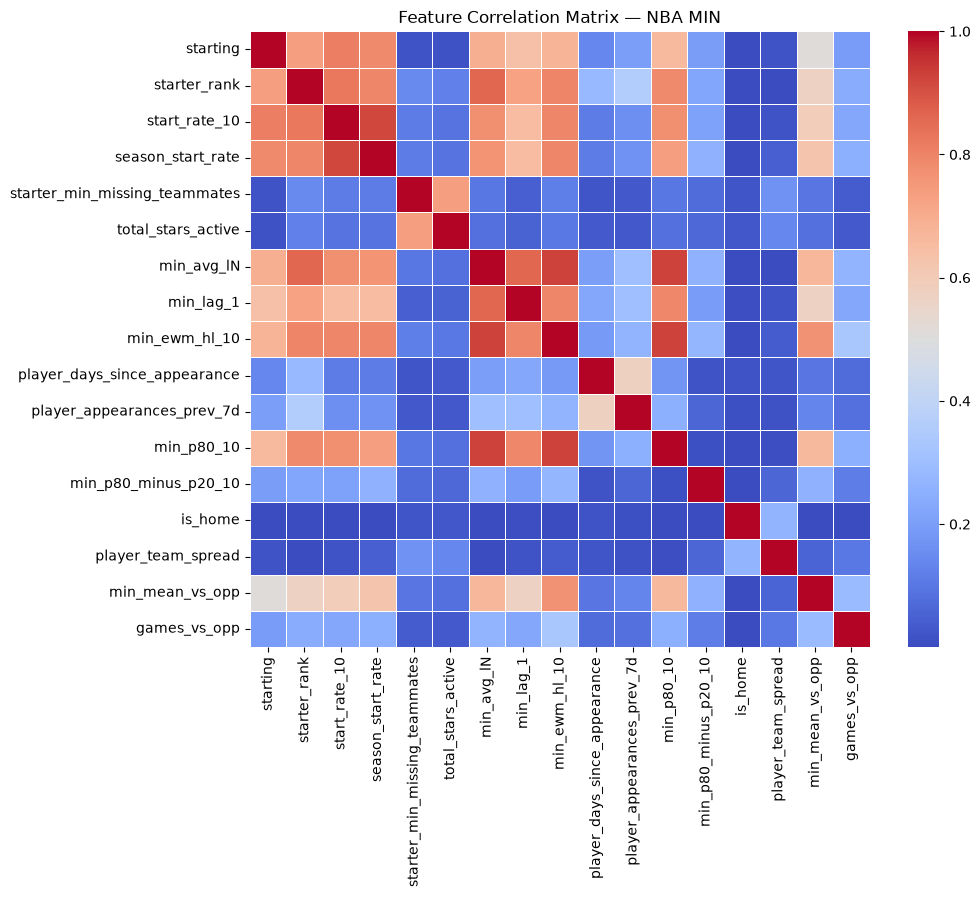

--- High Correlation Report (Threshold > 0.95) ---
No features exceed the correlation threshold.


[]

In [13]:
correlated_features = analyze_correlations(
    df, MIN_FEATURES, title="Feature Correlation Matrix — NBA MIN"
)
correlated_features


### Models

In [14]:
# Hyperparameter tuning
# Leave commented if you don't want to retune the model

# import importlib
# import models.shared.train as train
#
# importlib.reload(train)
# tune_xgb_quantile = train.tune_xgb_quantile
#
# result = tune_xgb_quantile(X, y, n_trials=50, n_splits=3)
# XGB_PARAMS = result["best_params"]


In [15]:
tscv_results = run_timeseries_cv(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    quantiles=QUANTILES,
)
wf = run_walk_forward(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    quantiles=QUANTILES,
    n_folds=5,
)

wf_results = wf["wf_results"]
models_last = wf["models_last"]
preds_last = wf["preds_last"]
X_val_last = wf["X_val_last"]
y_val_last = wf["y_val_last"]
starting_last = wf["starting_last"]
last_fold = wf["last_fold"]


── Phase 1: TimeSeriesSplit (XGBoost) ──────────────────────────

TSCV fold 1
  n=25010
  pinball  | q0.05=0.604  q0.10=1.005  q0.20=1.583  q0.30=1.947  q0.40=2.152  q0.50=2.217  q0.60=2.144  q0.70=1.936  q0.80=1.562  q0.90=0.987  q0.95=0.590
  coverage | 80%=78.4% (target 80%)  90%=89.0% (target 90%)
  Starters   | n=11707 | pinball q50: 2.102 | 80% coverage: 78.2%
  Bench      | n=13303 | pinball q50: 2.317 | 80% coverage: 78.5%
  minute tiers by predicted q50
  <15 min    | n= 5526 | pinball q50: 2.349 | 80% coverage: 77.9%
  15-24 min  | n= 7137 | pinball q50: 2.368 | 80% coverage: 78.6%
  24-31 min  | n= 6046 | pinball q50: 2.247 | 80% coverage: 79.1%
  31+ min    | n= 6301 | pinball q50: 1.899 | 80% coverage: 77.8%

TSCV fold 2
  n=25010
  pinball  | q0.05=0.631  q0.10=1.050  q0.20=1.639  q0.30=2.019  q0.40=2.227  q0.50=2.295  q0.60=2.220  q0.70=1.996  q0.80=1.606  q0.90=1.013  q0.95=0.604
  coverage | 80%=78.0% (target 80%)  90%=88.6% (target 90%)
  Starters   | n=11824 | pinbal

### Conformal calibration

Walk-forward out-of-fold rows only. Nothing here is fit on the 2025-26 holdout.

In [16]:
# One-sided conformal offsets on walk-forward OOF.
# Base knots are the sorted booster output, with each fold's cold-start
# role quantiles taken from that fold's training dates (the early-stopping
# tail is included there, and is not used as a calibration score).

from minutes_xgb.calibration import (
    calibration_table,
    fold_base_knots,
    nested_offset_backtest,
    oof_leakage_table,
    oof_player_games,
)
from minutes_xgb.config import N_BOOT, SEED
from models.shared.splits import date_walk_forward_folds
from src.models.settlement import maximum_minutes

MIN_N = 300
MAX_MINUTES = maximum_minutes("nba")

oof = wf["oof"].copy()
oof_player_games(oof, ppm_df)
n_folds = int(oof["fold_id"].nunique())
leak = oof_leakage_table(
    oof, ppm_df, date_walk_forward_folds(ppm_df, n_folds=n_folds)
)
display(leak)

base, group = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results]
)
print(pd.Series(group).value_counts().to_string())
y = oof["minutes"].to_numpy(dtype=float)
dates = pd.to_datetime(oof["game_date"]).to_numpy()
starting = oof["starting"].to_numpy()
oof = oof.reset_index(drop=True)
base = base.reset_index(drop=True)

print(
    f"\nGo/no-go on base knots. delta = P(y <= q) - tau, "
    f"with {N_BOOT:,} date-clustered resamples, seed {SEED}."
)
go_nogo = calibration_table(
    y, dates, base, group, starting=starting, n_boot=N_BOOT, seed=SEED
)
display(go_nogo.round(4))

backtest = nested_offset_backtest(
    oof,
    base,
    group,
    min_n=MIN_N,
    max_minutes=MAX_MINUTES,
    n_boot=N_BOOT,
    seed=SEED,
)
offset_tables = backtest["offset_tables"]
nested = backtest["nested"]
deltas = backtest["deltas"]
scores = backtest["scores"]
offset_flags = backtest["flags"]
for fold_id, table in offset_tables.items():
    print(f"\nOffsets fit on folds before {fold_id}")
    fold_counts = (
        backtest["counts"].loc[lambda frame: frame["fold"].eq(fold_id)].set_index("group")["n"]
    )
    print("rows per group:\n" + fold_counts.sort_index().to_string())
    omitted = fold_counts[fold_counts < MIN_N]
    if len(omitted):
        print("omitted (n < min_n):\n" + omitted.to_string())
    display(table.round(3))

print(
    "\nNested backtest, folds 3-5. diff = calibrated - raw. "
    "Lower WIS, CRPS, and pinball are better."
)
display(nested.round(4))
display(
    deltas.pivot_table(
        index=["fold", "version", "group"], columns="knot", values="delta"
    ).round(4)
)
display(scores.round(4))
print("\nOffset stability across fits on folds before k = 3, 4, 5")
if offset_flags.empty:
    print("No group/knot swings by more than its mean absolute offset.")
else:
    display(offset_flags.round(3))


,fold,train_end,val_start,val_end,n,val_in_train,val_in_stop,dates_match
0,1,2022-11-02,2022-11-03,2023-02-07,14737,0,0,True
1,2,2023-02-07,2023-02-08,2023-12-05,14919,0,0,True
2,3,2023-12-05,2023-12-06,2024-03-17,15346,0,0,True
3,4,2024-03-17,2024-03-18,2025-01-02,15441,0,0,True
4,5,2025-01-02,2025-01-03,2025-04-11,15267,0,0,True


31+           19666
15-24         19528
24-31         18162
<15           18122
cold_start      232

Go/no-go on base knots. delta = P(y <= q) - tau, with 2,000 date-clustered resamples, seed 42.


,n,empirical,target,delta,ci_low,ci_high,slice,check
0,75710,0.0533,0.05,0.0033,0.0015,0.0053,overall,q_0.05
1,75710,0.1061,0.10,0.0061,0.0036,0.0087,overall,q_0.10
2,75710,0.2053,0.20,0.0053,0.0020,0.0084,overall,q_0.20
3,75710,0.3053,0.30,0.0053,0.0014,0.0089,overall,q_0.30
4,75710,0.4034,0.40,0.0034,-0.0007,0.0073,overall,q_0.40
...,...,...,...,...,...,...,...,...
190,5868,0.7570,0.80,-0.0430,-0.0651,-0.0229,Apr,q_0.80
191,5868,0.8594,0.90,-0.0406,-0.0621,-0.0207,Apr,q_0.90
192,5868,0.9167,0.95,-0.0333,-0.0497,-0.0175,Apr,q_0.95
193,5868,0.7396,0.80,-0.0604,-0.0887,-0.0339,Apr,coverage_80



Offsets fit on folds before 3
rows per group:
group
15-24         7707
24-31         7029
31+           7952
<15           6870
cold_start      98
omitted (n < min_n):
group
cold_start    98


,n,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,,
<15,6870,-0.211,-0.169,-0.254,-0.210,-0.186,-0.170,-0.198,-0.066,0.012,0.302,0.574
15-24,7707,-0.323,-0.255,-0.058,-0.063,-0.052,-0.049,-0.053,-0.073,0.009,0.006,-0.023
24-31,7029,-0.152,-0.071,0.114,0.149,0.272,0.214,0.127,0.081,0.113,0.276,0.218
31+,7952,-0.382,-0.058,0.039,0.060,0.084,0.085,0.054,0.089,0.129,0.137,0.184



Offsets fit on folds before 4
rows per group:
group
15-24         11597
24-31         10728
31+           11898
<15           10656
cold_start      123
omitted (n < min_n):
group
cold_start    123


... (5 outputs left out)

knot                     q_0.05  q_0.10  q_0.20  q_0.30  q_0.40  q_0.50  \
fold version group                                                        
3    cal     15-24      -0.0107 -0.0049  0.0057  0.0062  0.0201  0.0195   
             24-31      -0.0070 -0.0035  0.0006 -0.0072  0.0009 -0.0023   
             31+        -0.0049  0.0006 -0.0036 -0.0070 -0.0031 -0.0132   
             <15         0.0049  0.0125  0.0129  0.0148  0.0099  0.0106   
             all        -0.0040  0.0020  0.0049  0.0026  0.0078  0.0043   
             cold_start  0.2700  0.5000  0.6800  0.5800  0.5200  0.4200   
     raw     15-24      -0.0076  0.0041  0.0067  0.0129  0.0247  0.0231   
             24-31      -0.0049 -0.0008 -0.0051 -0.0153 -0.0188 -0.0193   
             31+        -0.0013  0.0021 -0.0061 -0.0103 -0.0085 -0.0198   
             <15         0.0203  0.0252  0.0348  0.0323  0.0289  0.0243   
             all         0.0020  0.0084  0.0086  0.0058  0.0075  0.0028   
             cold_start  0.2700  0.5000  0.6800  0.5800  0.5200  0.4200   
4    cal     15-24       0.0027 -0.0056 -0.0156 -0.0192 -0.0228 -0.0073   
             24-31       0.0009  0.0007  0.0123  0.0162  0.0023  0.0039   
             31+        -0.0038 -0.0061 -0.0048 -0.0030 -0.0039  0.0053   
             <15        -0.0026  0.0003  0.0035  0.0058  0.0097 -0.0075   
             all        -0.0001 -0.0016  0.0007  0.0019 -0.0016  0.0004   
             cold_start  0.1307  0.2253  0.4145  0.4470  0.3952  0.3554   
     raw     15-24       0.0032 -0.0010 -0.0113 -0.0141 -0.0156  0.0014   
             24-31       0.0009  0.0016  0.0083  0.0047 -0.0126 -0.0179   
             31+        -0.0013 -0.0036 -0.0085 -0.0069 -0.0116 -0.0065   
             <15         0.0129  0.0276  0.0305  0.0338  0.0270  0.0055   
             all         0.0047  0.0074  0.0068  0.0067 -0.0008 -0.0021   
             cold_start  0.1307  0.2253  0.4145  0.4470  0.3952  0.3554   
5    cal     15-24      -0.0082 -0.0085  0.0001 -0.0014 -0.0014 -0.0082   
             24-31      -0.0040 -0.0084 -0.0170 -0.0060  0.0087  0.0062   
             31+        -0.0110 -0.0011 -0.0057  0.0147  0.0195  0.0222   
             <15        -0.0022 -0.0019 -0.0008 -0.0010  0.0035  0.0081   
             all        -0.0063 -0.0046 -0.0053  0.0020  0.0079  0.0072   
             cold_start  0.0654  0.2846  0.3385  0.3538  0.2923  0.2692   
     raw     15-24      -0.0070 -0.0045  0.0014  0.0011  0.0038 -0.0010   
             24-31      -0.0040 -0.0081 -0.0190 -0.0129 -0.0085 -0.0085   
             31+        -0.0081 -0.0008 -0.0095  0.0072  0.0106  0.0117   
             <15         0.0096  0.0175  0.0303  0.0317  0.0320  0.0208   
             all        -0.0025  0.0011  0.0008  0.0067  0.0093  0.0057   
             cold_start  0.0654  0.2846  0.3385  0.3538  0.2923  0.2692   

knot                     q_0.60  q_0.70  q_0.80  q_0.90  q_0.95  
fold version group                                               
3    cal     15-24       0.0265  0.0167  0.0090  0.0018 -0.0014  
             24-31      -0.0144 -0.0112 -0.0095 -0.0060 -0.0087  
             31+        -0.0295 -0.0355 -0.0319 -0.0209 -0.0101  
             <15         0.0112  0.0100  0.0016  0.0123  0.0022  
             all        -0.0010 -0.0047 -0.0075 -0.0032 -0.0044  
             cold_start  0.3600  0.2600  0.1600  0.1000  0.0500  
     raw     15-24       0.0308  0.0190  0.0080  0.0018 -0.0014  
             24-31      -0.0258 -0.0177 -0.0157 -0.0184 -0.0130  
             31+        -0.0344 -0.0411 -0.0425 -0.0298 -0.0177  
             <15         0.0233  0.0124  0.0014  0.0060 -0.0018  
             all        -0.0009 -0.0065 -0.0121 -0.0100 -0.0084  
             cold_start  0.3600  0.2600  0.1600  0.1000  0.0500  
4    cal     15-24      -0.0202 -0.0201 -0.0091 -0.0034 -0.0035  
             24-31       0.0109 -0.0044  0.0103  0.0104  0.0028  
             31+         0.0093  0.0005 -0.0036 -0.0023 -0.0061  
             <15        -0.

,fold,n,reorder,pinball_q50_raw,pinball_q50_cal,wis_raw,wis_cal,wis_diff,wis_ci_low,wis_ci_high,crps_raw,crps_cal,crps_diff,crps_ci_low,crps_ci_high
0,3,15346,0.0044,2.2243,2.2224,3.0477,3.0449,-0.0028,-0.0047,-0.0008,3.0477,3.0449,-0.0028,-0.0047,-0.0008
1,4,15441,0.0059,2.2398,2.2397,3.0714,3.0709,-0.0005,-0.0034,0.0022,3.0714,3.0709,-0.0005,-0.0034,0.0022
2,5,15267,0.0037,2.2048,2.2048,3.0194,3.0202,0.0008,-0.0015,0.0031,3.0194,3.0202,0.0008,-0.0015,0.0031



Offset stability across fits on folds before k = 3, 4, 5


,group,knot,swing,mean_abs,offsets
0,<15,q_0.80,0.033,0.012,"0.012, -0.002, -0.021"
1,<15,q_0.90,0.286,0.136,"0.302, 0.090, 0.016"
2,<15,q_0.95,0.417,0.406,"0.574, 0.487, 0.157"
3,15-24,q_0.05,0.282,0.153,"-0.323, -0.041, -0.096"
4,15-24,q_0.20,0.075,0.054,"-0.058, -0.089, -0.015"
5,15-24,q_0.30,0.066,0.061,"-0.063, -0.093, -0.027"
6,15-24,q_0.40,0.096,0.087,"-0.052, -0.147, -0.063"
7,15-24,q_0.60,0.134,0.116,"-0.053, -0.187, -0.108"
8,15-24,q_0.80,0.068,0.024,"0.009, -0.059, -0.004"
9,15-24,q_0.90,0.020,0.009,"0.006, -0.012, 0.008"


In [17]:
wf_pinball, wf_coverage = score_predictions(
    y_val_last, preds_last, last_fold["fold"]
)
display(wf_pinball.round(4))
display(wf_coverage.round(4))


,split,quantile,pinball
0,WF fold 5 (2025-01-02 → 2025-04-11),0.05,0.6034
1,WF fold 5 (2025-01-02 → 2025-04-11),0.10,0.9995
2,WF fold 5 (2025-01-02 → 2025-04-11),0.20,1.5670
3,WF fold 5 (2025-01-02 → 2025-04-11),0.30,1.9283
4,WF fold 5 (2025-01-02 → 2025-04-11),0.40,2.1302
5,WF fold 5 (2025-01-02 → 2025-04-11),0.50,2.2023
6,WF fold 5 (2025-01-02 → 2025-04-11),0.60,2.1249
7,WF fold 5 (2025-01-02 → 2025-04-11),0.70,1.9159
8,WF fold 5 (2025-01-02 → 2025-04-11),0.80,1.5492
9,WF fold 5 (2025-01-02 → 2025-04-11),0.90,0.9855


,split,interval,coverage,target
0,WF fold 5 (2025-01-02 → 2025-04-11),80%,0.8047,0.8
1,WF fold 5 (2025-01-02 → 2025-04-11),90%,0.9016,0.9


In [18]:
holdout = evaluate_holdout(
    ppm_df,
    ppm_holdout,
    features=MIN_FEATURES,
    target_col=TARGET_COL,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    wf_results=wf_results,
    quantiles=QUANTILES,
    fold_label=f"{HOLDOUT_SEASON} Blind Holdout",
)
models_ho = holdout["models_ho"]
preds_ho = holdout["preds_ho"]
ho_metrics = holdout["ho_metrics"]
X_ho = holdout["X_ho"]
y_ho = holdout["y_ho"]

ho_pinball, ho_coverage = score_predictions(
    y_ho, preds_ho, f"{HOLDOUT_SEASON} holdout"
)
display(ho_pinball.round(4))
display(ho_coverage.round(4))


── 2025-26 Blind Holdout ─────────────────────────────────────────────────
  Train pool: last 10% of training dates for early-stopping only; predict holdout (never in eval_set).

2025-26 Blind Holdout
  n=26648
  pinball  | q0.05=0.612  q0.10=1.013  q0.20=1.585  q0.30=1.951  q0.40=2.154  q0.50=2.218  q0.60=2.147  q0.70=1.937  q0.80=1.568  q0.90=0.994  q0.95=0.589
  coverage | 80%=79.9% (target 80%)  90%=89.8% (target 90%)
  Starters   | n=12300 | pinball q50: 2.077 | 80% coverage: 81.4%
  Bench      | n=14348 | pinball q50: 2.339 | 80% coverage: 78.7%
  minute tiers by predicted q50
  <15 min    | n= 6228 | pinball q50: 2.416 | 80% coverage: 78.1%
  15-24 min  | n= 7572 | pinball q50: 2.332 | 80% coverage: 79.3%
  24-31 min  | n= 7162 | pinball q50: 2.173 | 80% coverage: 80.9%
  31+ min    | n= 5686 | pinball q50: 1.907 | 80% coverage: 81.6%

───────────────────────────────────────────────────────
  Walk-forward pinball q50 (mean) : 2.225
  Holdout pinball q50             : 2.218
  Pin

,split,quantile,pinball
0,2025-26 holdout,0.05,0.6116
1,2025-26 holdout,0.10,1.0133
2,2025-26 holdout,0.20,1.5855
3,2025-26 holdout,0.30,1.9507
4,2025-26 holdout,0.40,2.1539
5,2025-26 holdout,0.50,2.2182
6,2025-26 holdout,0.60,2.1466
7,2025-26 holdout,0.70,1.9370
8,2025-26 holdout,0.80,1.5679
9,2025-26 holdout,0.90,0.9941


,split,interval,coverage,target
0,2025-26 holdout,80%,0.7995,0.8
1,2025-26 holdout,90%,0.8980,0.9


### Date-tail holdout, raw beside calibrated

Early stopping uses the last 10% of training dates. Offsets are the all-fold walk-forward table. The 2025-26 rows are scored, not fit.


In [19]:
# 8c. Date-tail holdout, raw knots beside calibrated knots.
# Offsets are fit on every walk-forward validation fold. Nothing here is
# fit on the 2025-26 rows. Raw is the booster output. Calibrated is
# sort, cold-start fallback, offset, sort, clip.

from minutes_xgb.calibration import fold_base_knots
from minutes_xgb.config import MIN_TIERS, N_BOOT, QUANTILES, SEED
from minutes_xgb.scoring import (
    holdout_point_distribution,
    interval_sharpness,
    predicted_minute_tiers,
    quantile_calibration,
    quantile_crossing,
    tail_calibration_rows,
    wis_values,
)
from minutes_xgb.slices import regular_season_blocks, slice_score
from models.shared.conformal import (
    apply_offsets,
    base_knots,
    calibration_group,
    calibration_payload,
    fit_offsets,
    role_quantile_table,
)
from models.shared.metrics import paired_date_bootstrap
from models.shared.minutes_sampler import (
    build_tail_tables,
    save_tail_sidecar,
    tail_miss_rates,
    within_miss_rate_band,
)
from src.models.settlement import maximum_minutes

MIN_N = 300
MAX_MINUTES = maximum_minutes("nba")
oof = wf["oof"].copy()
knots = [f"q_{level:.2f}" for level in QUANTILES]
levels = {key: float(key.split("_", 1)[1]) for key in knots}

print(
    "Previous row-tail holdout (saved notebook run, last 10% of rows): "
    "q50 pinball 2.220, 80% coverage 80.0%, 90% coverage 89.6%."
)
print(
    "Date-tail holdout (last 10% of training dates): "
    f"q50 pinball {ho_metrics['pinball']:.3f}, "
    f"80% coverage {ho_metrics['coverage_80pct']:.1%}, "
    f"90% coverage {ho_metrics['coverage_90pct']:.1%}."
)

base_oof, group_oof = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results]
)
offsets_all = fit_offsets(base_oof, oof["minutes"], group_oof, levels, min_n=MIN_N)
oof_cal = apply_offsets(base_oof, group_oof, offsets_all, MAX_MINUTES)
role_quantiles = role_quantile_table(ppm_df[["starting", "minutes"]], QUANTILES)
base_ho = base_knots(
    preds_ho,
    ppm_holdout["starting"],
    ppm_holdout["min_lag_1"],
    role_quantiles=role_quantiles,
)
group_ho = calibration_group(base_ho["q_0.50"], ppm_holdout["min_lag_1"])
preds_ho_cal = apply_offsets(base_ho, group_ho, offsets_all, MAX_MINUTES)
calibration_record = calibration_payload(
    offsets_all,
    group_oof,
    oof["game_date"],
    min_n=MIN_N,
    role_quantiles=role_quantiles,
    max_minutes=MAX_MINUTES,
)
print("OOF calibration rows", calibration_record["date_start"], "→", calibration_record["date_end"])
print("row counts", calibration_record["row_counts"])
display(offsets_all.round(3))

raw_map = {key: np.asarray(preds_ho[key], dtype=float) for key in knots}
cal_map = {key: preds_ho_cal[key].to_numpy(dtype=float) for key in knots}
base_map = {key: base_ho[key].to_numpy(dtype=float) for key in knots}
shift = offsets_all.reindex(pd.Index(group_ho)).fillna(0.0)
shift.index = base_ho.index
added = base_ho[knots].to_numpy() + shift[knots].to_numpy()
reorder = float(np.mean(np.any(np.diff(added, axis=1) < 0, axis=1)))
raw_cross, raw_n, _ = quantile_crossing(raw_map)
cal_cross, _, _ = quantile_crossing(cal_map)
print(
    f"Crossing rows: raw {raw_cross}/{raw_n} ({raw_cross / raw_n:.2%}), "
    f"calibrated {cal_cross}/{raw_n} ({cal_cross / raw_n:.2%}). "
    f"Second-sort reorder after the offset: {reorder:.2%}."
)

calibration_side = pd.concat(
    [
        quantile_calibration(y_ho, raw_map).assign(version="raw"),
        quantile_calibration(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Holdout calibration. delta = P(y ≤ q) − τ")
display(
    calibration_side.pivot(index="quantile", columns="version", values="delta").round(4)
)

tiers = pd.concat(
    [
        predicted_minute_tiers(y_ho, raw_map, MIN_TIERS).assign(version="raw"),
        predicted_minute_tiers(y_ho, cal_map, MIN_TIERS).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Predicted-minute tiers")
display(tiers.round(4))

point_table = pd.DataFrame(
    [
        holdout_point_distribution("raw", y_ho, raw_map),
        holdout_point_distribution("calibrated", y_ho, cal_map),
    ]
)
tail_table = pd.DataFrame(
    tail_calibration_rows("raw", y_ho, raw_map)
    + tail_calibration_rows("calibrated", y_ho, cal_map)
)
sharp = pd.concat(
    [
        interval_sharpness(y_ho, raw_map).assign(version="raw"),
        interval_sharpness(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("q50 RMSE and 11-knot CRPS. CRPS is twice the mean pinball at the trained knots.")
display(point_table.round(4))
print("Tail calibration. delta = empirical − nominal")
display(tail_table.round(4))
print("Interval sharpness")
display(sharp.round(4))

dates = pd.to_datetime(ppm_holdout["game_date"])
starting = ppm_holdout["starting"].to_numpy()
lag = ppm_holdout["min_lag_1"].to_numpy(dtype=float)
masks = {
    **regular_season_blocks(dates),
    "Confirmed starter": starting == 1,
    "Bench": starting == 0,
    "No prior game": ~np.isfinite(lag),
}
slice_rows = []
for name, mask in masks.items():
    chosen = np.asarray(mask, dtype=bool)
    slice_rows.append({**slice_score(name, chosen, y_ho, raw_map), "version": "raw"})
    slice_rows.append(
        {**slice_score(name, chosen, y_ho, cal_map), "version": "calibrated"}
    )
    if name == "No prior game":
        slice_rows.append(
            {**slice_score(name, chosen, y_ho, base_map), "version": "base fallback"}
        )
print("Calendar, role, and cold-start slices")
display(pd.DataFrame(slice_rows).round(4))


def _row_pinball(actual, pred, alpha=0.50):
    residual = np.asarray(actual, dtype=float) - np.asarray(pred, dtype=float)
    return np.where(residual >= 0, alpha * residual, (alpha - 1.0) * residual)


pin_ci = paired_date_bootstrap(
    _row_pinball(y_ho, raw_map["q_0.50"]),
    _row_pinball(y_ho, cal_map["q_0.50"]),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
wis_ci = paired_date_bootstrap(
    wis_values(y_ho, raw_map),
    wis_values(y_ho, cal_map),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
in_raw = (
    (np.asarray(y_ho, dtype=float) >= raw_map["q_0.10"])
    & (np.asarray(y_ho, dtype=float) <= raw_map["q_0.90"])
).astype(float)
in_cal = (
    (np.asarray(y_ho, dtype=float) >= cal_map["q_0.10"])
    & (np.asarray(y_ho, dtype=float) <= cal_map["q_0.90"])
).astype(float)
cov_ci = paired_date_bootstrap(in_raw, in_cal, dates, n_boot=N_BOOT, seed=SEED)
print(
    "Date-clustered 95% CI, calibrated − raw. "
    f"q50 pinball {pin_ci['diff']:+.4f} "
    f"[{pin_ci['ci_low']:+.4f}, {pin_ci['ci_high']:+.4f}]. "
    f"WIS {wis_ci['diff']:+.4f} "
    f"[{wis_ci['ci_low']:+.4f}, {wis_ci['ci_high']:+.4f}]. "
    f"80% coverage {cov_ci['diff']:+.4f} "
    f"[{cov_ci['ci_low']:+.4f}, {cov_ci['ci_high']:+.4f}]."
)

print(
    "\nTail miss rates on the next fold. Tables are fit on earlier calibrated folds only."
)
miss_rows = []
for k in (3, 4, 5):
    past_ids = list(range(1, k))
    past = oof["fold_id"].isin(past_ids).to_numpy()
    offsets_k = fit_offsets(
        base_oof.loc[past],
        oof.loc[past, "minutes"],
        group_oof[past],
        levels,
        min_n=MIN_N,
    )
    past_cal = apply_offsets(
        base_oof.loc[past], group_oof[past], offsets_k, MAX_MINUTES
    )
    past_frame = oof.loc[
        past,
        [
            "fold_id",
            "game_date",
            "minutes",
            "starting",
            "early_stop",
            "train_tail_frac",
        ],
    ].copy()
    for column in knots:
        past_frame[column] = past_cal[column].to_numpy()
    build_tail_tables(
        past_frame.reset_index(drop=True),
        folds=past_ids,
        fold_ranges=wf["fold_ranges"],
        check_miss_rate=False,
    )
    test = oof["fold_id"].to_numpy() == k
    test_cal = apply_offsets(
        base_oof.loc[test], group_oof[test], offsets_k, MAX_MINUTES
    )
    raw_lower, raw_upper = tail_miss_rates(
        oof.loc[test, "minutes"],
        base_oof.loc[test, "q_0.05"],
        base_oof.loc[test, "q_0.95"],
    )
    cal_lower, cal_upper = tail_miss_rates(
        oof.loc[test, "minutes"],
        test_cal["q_0.05"],
        test_cal["q_0.95"],
    )
    miss_rows.append(
        {
            "fold": k,
            "raw_lower": raw_lower,
            "raw_upper": raw_upper,
            "cal_lower": cal_lower,
            "cal_upper": cal_upper,
            "raw_in_band": within_miss_rate_band(raw_lower, raw_upper),
            "cal_in_band": within_miss_rate_band(cal_lower, cal_upper),
        }
    )
miss_rates = pd.DataFrame(miss_rows)
display(miss_rates.round(4))

ship = oof[
    ["fold_id", "game_date", "minutes", "starting", "early_stop", "train_tail_frac"]
].copy()
for column in knots:
    ship[column] = oof_cal[column].to_numpy()
tail_tables = build_tail_tables(
    ship.reset_index(drop=True),
    folds=[1, 2, 3, 4, 5],
    fold_ranges=wf["fold_ranges"],
    check_miss_rate=False,
)
tail_path = ROOT / "models/saved_models/min_nba_tails_cal_2026-04-12.joblib"
save_tail_sidecar(tail_tables, tail_path)
print(f"Wrote calibrated tail tables to {tail_path.relative_to(ROOT)}")


Previous row-tail holdout (saved notebook run, last 10% of rows): q50 pinball 2.220, 80% coverage 80.0%, 90% coverage 89.6%.
Date-tail holdout (last 10% of training dates): q50 pinball 2.218, 80% coverage 79.9%, 90% coverage 89.8%.
OOF calibration rows 2022-11-03 → 2025-04-11
row counts {'cold_start': 232, '<15': 18122, '15-24': 19528, '24-31': 18162, '31+': 19666}


,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
group,,,,,,,,,,,
<15,-0.226,-0.252,-0.307,-0.331,-0.265,-0.212,-0.192,-0.093,-0.009,0.017,0.182
15-24,0.037,-0.071,-0.016,-0.025,-0.059,-0.086,-0.097,-0.088,-0.012,0.000,0.076
24-31,0.028,0.023,0.124,0.149,0.225,0.194,0.121,0.101,0.066,0.115,0.182
31+,-0.046,-0.007,0.121,0.061,0.065,0.070,0.062,0.145,0.175,0.199,0.370


Crossing rows: raw 528/26648 (1.98%), calibrated 0/26648 (0.00%). Second-sort reorder after the offset: 0.32%.
Holdout calibration. delta = P(y ≤ q) − τ


version,calibrated,raw
quantile,,
0.05,-0.0004,0.0015
0.10,-0.0021,0.0012
0.20,-0.0002,0.0004
0.30,0.0029,0.0045
0.40,0.0085,0.0070
0.50,0.0061,0.0058
0.60,0.0061,0.0063
0.70,0.0104,0.0064
0.80,0.0120,0.0078


Predicted-minute tiers


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90,version
0,<15 min,6228,0.2337,2.4159,0.4994,0.7808,0.8847,14.9812,18.9152,raw
1,15-24 min,7572,0.2841,2.3320,0.4871,0.7928,0.8973,15.0539,19.7155,raw
2,24-31 min,7162,0.2688,2.1728,0.5156,0.8093,0.9031,13.9983,18.0785,raw
3,31+ min,5686,0.2134,1.9072,0.5253,0.8164,0.9073,12.1431,16.1270,raw
4,<15 min,6191,0.2323,2.4120,0.4826,0.7958,0.8979,15.2254,19.3015,calibrated
5,15-24 min,7607,0.2855,2.3613,0.4848,0.7941,0.8980,15.2218,19.8477,calibrated
6,24-31 min,6945,0.2606,2.1780,0.5294,0.8137,0.9073,14.1138,18.2604,calibrated
7,31+ min,5905,0.2216,1.9175,0.5306,0.8246,0.9136,12.3863,16.5756,calibrated


... (7 outputs left out)

,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis,version
0,October–February,19417,4.3846,-0.1326,0.5080,0.8056,14.1391,3.0174,raw
1,October–February,19417,4.4062,-0.1612,0.5085,0.8120,14.3154,3.0295,calibrated
2,March 1–14,2364,4.4329,0.0266,0.4949,0.7948,14.0448,3.0297,raw
3,March 1–14,2364,4.4329,-0.0086,0.4958,0.8025,14.2137,3.0241,calibrated
4,March 15–31,2806,4.3873,-0.1483,0.5153,0.7972,13.9689,2.9863,raw
5,March 15–31,2806,4.4080,-0.1811,0.5135,0.8058,14.1383,2.9946,calibrated
6,April regular season,2061,4.9942,0.4151,0.4847,0.7496,14.3886,3.4499,raw
7,April regular season,2061,4.9910,0.4019,0.4847,0.7589,14.5457,3.4449,calibrated
8,Confirmed starter,12300,4.1538,-0.6473,0.5214,0.8140,13.3050,2.8813,raw
9,Confirmed starter,12300,4.1603,-0.7702,0.5305,0.8200,13.4478,2.8855,calibrated


Date-clustered 95% CI, calibrated − raw. q50 pinball +0.0088 [+0.0052, +0.0126]. WIS +0.0088 [+0.0047, +0.0128]. 80% coverage +0.0069 [+0.0059, +0.0080].

Tail miss rates on the next fold. Tables are fit on earlier calibrated folds only.


,fold,raw_lower,raw_upper,cal_lower,cal_upper,raw_in_band,cal_in_band
0,3,0.0520,0.0584,0.0460,0.0544,True,True
1,4,0.0547,0.0543,0.0499,0.0490,True,True
2,5,0.0475,0.0510,0.0437,0.0474,True,True


Wrote calibrated tail tables to models/saved_models/min_nba_tails_cal_2026-04-12.joblib


In [20]:
calibration = quantile_calibration(y_ho, preds_ho)
print(f"{HOLDOUT_SEASON} holdout — empirical quantile calibration")
display(calibration.round(4))


2025-26 holdout — empirical quantile calibration


,quantile,target,empirical,delta
0,0.05,0.05,0.0515,0.0015
1,0.10,0.10,0.1012,0.0012
2,0.20,0.20,0.2004,0.0004
3,0.30,0.30,0.3045,0.0045
4,0.40,0.40,0.4070,0.0070
5,0.50,0.50,0.5058,0.0058
6,0.60,0.60,0.6063,0.0063
7,0.70,0.70,0.7064,0.0064
8,0.80,0.80,0.8078,0.0078
9,0.90,0.90,0.9007,0.0007


In [21]:
n_crossed, n_rows, crossing_pairs = quantile_crossing(preds_ho)
print(
    f"{HOLDOUT_SEASON} holdout quantile crossing: "
    f"{n_crossed:,} / {n_rows:,} rows ({n_crossed / n_rows:.1%})"
)
display(crossing_pairs.round(4))


2025-26 holdout quantile crossing: 528 / 26,648 rows (2.0%)


,lower,upper,crossing_rate
0,q_0.05,q_0.10,0.0009
1,q_0.10,q_0.20,0.0009
2,q_0.20,q_0.30,0.0032
3,q_0.30,q_0.40,0.0039
4,q_0.40,q_0.50,0.0042
5,q_0.50,q_0.60,0.0036
6,q_0.60,q_0.70,0.0020
7,q_0.70,q_0.80,0.0019
8,q_0.80,q_0.90,0.0007
9,q_0.90,q_0.95,0.0003


In [22]:
tier_report = predicted_minute_tiers(y_ho, preds_ho, MIN_TIERS)
print(f"{HOLDOUT_SEASON} holdout — minute tiers by predicted q50")
display(tier_report.round(4))


2025-26 holdout — minute tiers by predicted q50


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90
0,<15 min,6228,0.2337,2.4159,0.4994,0.7808,0.8847,14.9812,18.9152
1,15-24 min,7572,0.2841,2.3320,0.4871,0.7928,0.8973,15.0539,19.7155
2,24-31 min,7162,0.2688,2.1728,0.5156,0.8093,0.9031,13.9983,18.0785
3,31+ min,5686,0.2134,1.9072,0.5253,0.8164,0.9073,12.1431,16.1270


In [23]:
score_table = pd.DataFrame([
    holdout_point_distribution("XGBoost", y_ho, preds_ho)
])
tail_calibration = pd.DataFrame(
    tail_calibration_rows("XGBoost", y_ho, preds_ho)
)
print(
    f"{HOLDOUT_SEASON} holdout — q50 RMSE and 11-knot CRPS\n"
    "  CRPS is twice the mean pinball across the trained knots"
)
display(score_table.round(4))
print(
    f"{HOLDOUT_SEASON} holdout — tail calibration\n"
    "  delta is empirical minus nominal. "
    "A positive delta means more outcomes landed in that tail than the quantile claims"
)
display(tail_calibration.round(4))


2025-26 holdout — q50 RMSE and 11-knot CRPS
  CRPS is twice the mean pinball across the trained knots


,model,rmse,crps
0,XGBoost,5.8397,3.0487


2025-26 holdout — tail calibration
  delta is empirical minus nominal. A positive delta means more outcomes landed in that tail than the quantile claims


,model,side,quantile,nominal,empirical,delta
0,XGBoost,lower,0.05,0.05,0.0515,0.0015
1,XGBoost,lower,0.10,0.10,0.1012,0.0012
2,XGBoost,upper,0.90,0.10,0.0993,-0.0007
3,XGBoost,upper,0.95,0.05,0.0504,0.0004


In [24]:
sharp_xgb = interval_sharpness(y_ho, preds_ho)
print(f"{HOLDOUT_SEASON} holdout — interval sharpness (minutes)")
display(sharp_xgb.round(4))


2025-26 holdout — interval sharpness (minutes)


,interval,coverage,target,mean_width,median_width
0,80%,0.7995,0.8,14.1321,13.8451
1,90%,0.8980,0.9,18.3228,18.0439


### Baseline

In [25]:
report = compare_to_baselines(
    y_ho,
    preds_ho,
    ppm_holdout,
    ppm_df,
    wf_results,
)
print("1. Point accuracy versus baselines")
print(
    f"Identical holdout rows: {report['paired_n']:,}  |  "
    f"dropped {report['dropped_n']:,} with a missing baseline  |  "
    f"{report['n_boot']:,} date-clustered resamples"
)
print(
    "Mean bias is actual minus predicted. "
    f"XGBoost q50 pinball {report['q50_pinball']:.4f}. "
    "That equals half the q50 MAE."
)
display(report["point_table"].round(3))
print(
    "Paired MAE difference, clustered by game date. "
    "Negative means XGBoost q50 is lower."
)
display(report["delta_table"].round(3))
print(
    "Walk-forward MAE is 2 × q50 pinball on every validation row. "
    "Baseline MAE drops rows with no prior."
)
display(report["fold_table"].round(3))

print("\n2. Distribution quality")
knots = ", ".join(report["wis_knots"]) if report["wis_knots"] else "median only"
print(f"WIS uses the trained knots only: {knots}, plus the q50 term.")
display(report["distribution"].round(4))
print(
    f"Best baseline MAE {report['best_mae']:.3f} "
    f"({report['best_name']}) is that point forecast's CRPS."
)

print("\n3. Calibration of every quantile")
display(report["calibration"].round(4))

print("\n4. Pregame-defined subgroups")
print("Minute tiers use predicted q50.")
display(report["subgroup_table"].round(3))

print("\n5. Tail failures")
display(report["tail_table"].round(4))
print("\nChecks from this frame")
for line in report["checks"]:
    print(f"  {line}")


1. Point accuracy versus baselines
Identical holdout rows: 26,544  |  dropped 104 with a missing baseline  |  2,000 date-clustered resamples
Mean bias is actual minus predicted. XGBoost q50 pinball 2.2152. That equals half the q50 MAE.


,model,mae,median_ae,mean_bias
0,Last-game minutes,5.864,4.450,0.007
1,EWMA minutes,5.306,4.179,0.200
2,Quantile XGBoost q50,4.430,3.463,-0.089


Paired MAE difference, clustered by game date. Negative means XGBoost q50 is lower.


,comparison,delta_mae,ci_low,ci_high
0,XGBoost q50 − Last-game minutes,-1.434,-1.526,-1.349
1,XGBoost q50 − EWMA minutes,-0.876,-0.961,-0.803


Walk-forward MAE is 2 × q50 pinball on every validation row. Baseline MAE drops rows with no prior.


,fold,n,model_mae,last_game,ewma,best_baseline,model_minus_best
0,WF fold 1 (2022-11-02 → 2023-02-07),14737,4.474,5.936,5.239,5.239,-0.766
1,WF fold 2 (2023-02-07 → 2023-12-05),14919,4.486,5.988,5.463,5.463,-0.978
2,WF fold 3 (2023-12-05 → 2024-03-17),15346,4.434,5.783,5.224,5.224,-0.789
3,WF fold 4 (2024-03-17 → 2025-01-02),15441,4.452,5.830,5.374,5.374,-0.922
4,WF fold 5 (2025-01-02 → 2025-04-11),15267,4.405,5.875,5.305,5.305,-0.900


... (5 outputs left out)

,model,group,n,mae,bias,wis,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median
0,Quantile XGBoost,Confirmed starter,12300,4.154,-0.647,2.881,0.814,13.305,13.113,0.906,17.349,17.065
1,Quantile XGBoost,Bench,14348,4.679,0.411,3.192,0.787,14.841,14.733,0.892,19.157,19.105
2,Quantile XGBoost,Predicted q50 <15 min,6228,4.832,0.825,3.258,0.781,14.981,15.292,0.885,18.915,19.224
3,Quantile XGBoost,Predicted q50 15-24 min,7572,4.664,0.140,3.208,0.793,15.054,14.797,0.897,19.716,19.522
4,Quantile XGBoost,Predicted q50 24-31 min,7162,4.346,-0.464,2.993,0.809,13.998,13.767,0.903,18.079,17.805
5,Quantile XGBoost,Predicted q50 31+ min,5686,3.814,-0.870,2.677,0.816,12.143,12.009,0.907,16.127,15.859
6,Quantile XGBoost,2025-10,1791,4.519,-0.065,3.116,0.800,14.419,14.115,0.888,18.499,18.325
7,Quantile XGBoost,2025-11,4784,4.338,-0.114,2.988,0.806,14.029,13.788,0.905,18.179,17.977
8,Quantile XGBoost,2025-12,4265,4.414,-0.135,3.045,0.802,14.145,13.898,0.891,18.292,18.036
9,Quantile XGBoost,2026-01,4987,4.215,-0.221,2.900,0.819,14.043,13.773,0.911,18.199,17.902



5. Tail failures


,model,threshold,rate,n
0,Quantile XGBoost,>5 min,0.3452,9199
1,Quantile XGBoost,>10 min,0.0842,2245
2,Quantile XGBoost,>15 min,0.0194,517



Checks from this frame
  Quantile XGBoost q50 observed rate 50.6%  (target about 48–52%)
  Quantile XGBoost largest |quantile gap| 0.8%
  XGBoost q50 vs EWMA minutes: delta MAE -0.876 [-0.961, -0.803]
  WIS 3.049 (XGBoost) vs best baseline CRPS/MAE 5.306
  walk-forward folds with XGBoost MAE below the best baseline: 5 / 5
  raw quantile crossing 1.98%


### Features Analysis

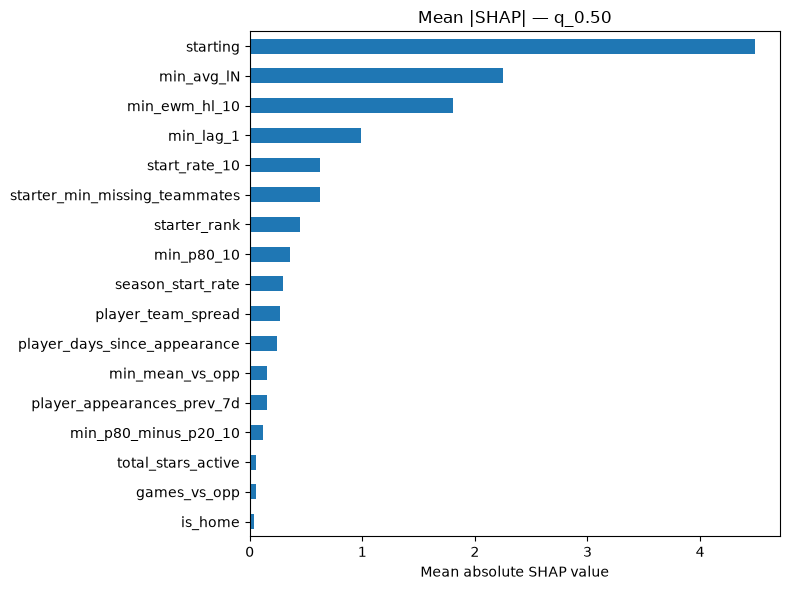

In [26]:
feat_imp = mean_absolute_shap(models_last["q_0.50"], X_val_last)
plot_shap(feat_imp)
plt.show()


In [27]:
pi_df, perm_result = permutation_importance_table(
    models_last["q_0.50"],
    X_val_last,
    y_val_last,
)
print(
    "Permutation importance (val set) — higher = more important, "
    "significant = p<0.05"
)
print(pi_df.to_string())


Permutation importance (val set) — higher = more important, significant = p<0.05
                          feature  importance      std  p_value  significant
1                        starting     0.98572  0.01220   0.0000         True
2                      min_avg_lN     0.49960  0.00692   0.0000         True
3                   min_ewm_hl_10     0.36123  0.00617   0.0000         True
4                    starter_rank     0.21433  0.00445   0.0000         True
5                       min_lag_1     0.14803  0.00461   0.0000         True
6                   start_rate_10     0.09035  0.00390   0.0000         True
7   starter_min_missing_teammates     0.06798  0.00356   0.0000         True
8                      min_p80_10     0.03977  0.00202   0.0000         True
9               season_start_rate     0.03615  0.00252   0.0000         True
10             player_team_spread     0.02895  0.00240   0.0000         True
11   player_days_since_appearance     0.01747  0.00209   0.0000         

In [28]:
train_mask_last = last_fold["train_mask"]
val_mask_last = last_fold["val_mask"]
X_tr_last = X.loc[train_mask_last]
X_va_last = X.loc[val_mask_last]
y_tr_last = ppm_df.loc[train_mask_last, TARGET_COL]
y_va_last = ppm_df.loc[val_mask_last, TARGET_COL]

ablation_df = run_feature_ablation(
    MIN_FEATURES, X_tr_last, y_tr_last, X_va_last, y_va_last,
    xgb_params=XGB_PARAMS,
)


Baseline pinball q50 (all features): 2.1971
                          feature  ablated_pinball  delta_pinball
1                        starting           2.2930         0.0958
2                       min_lag_1           2.2137         0.0166
3   starter_min_missing_teammates           2.2108         0.0137
4                   min_ewm_hl_10           2.2102         0.0131
5                    starter_rank           2.2064         0.0093
6                   start_rate_10           2.2048         0.0077
7              player_team_spread           2.2034         0.0063
8                      min_avg_lN           2.1994         0.0023
9      player_appearances_prev_7d           2.1993         0.0022
10             total_stars_active           2.1992         0.0021
11                     min_p80_10           2.1982         0.0010
12   player_days_since_appearance           2.1974         0.0002
13                        is_home           2.1971        -0.0000
14              season_start_rat

In [29]:
feature_audit = feature_consensus(
    list(X_val_last.columns),
    feat_imp,
    pi_df,
    perm_result.importances,
    ablation_df,
)
print(feature_audit.to_string())


                          feature  mean_abs_shap  shap_rank  perm_rank  perm_importance  perm_importance_std   perm_pvalue  ablation_delta  shap_norm  perm_norm  consensus   keep
1                        starting       4.485448          1          1          0.98572              0.01220  7.029844e-57          0.0958   1.000000   1.000000   1.000000   True
2                      min_avg_lN       2.250073          2          2          0.49960              0.00692  1.881848e-55          0.0023   0.501639   0.506838   0.504238   True
3                   min_ewm_hl_10       1.807425          3          3          0.36123              0.00617  8.117965e-53          0.0131   0.402953   0.366463   0.384708   True
4                       min_lag_1       0.988052          4          5          0.14803              0.00461  2.959524e-45          0.0166   0.220279   0.150174   0.185227   True
5                    starter_rank       0.447274          7          4          0.21433              0.00

### Slice Analysis

In [30]:
dates = pd.to_datetime(ppm_holdout["game_date"])
raw_q = {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()}
blocks = regular_season_blocks(dates)

print("1. April is late regular season, not the postseason")
holdout_season = df.loc[df["season_year"].astype("string").eq(str(HOLDOUT_SEASON))]
print(holdout_season["season_type"].astype("string").value_counts(dropna=False).to_string())
print(
    f"Holdout dates {dates.min().date()} → {dates.max().date()}. "
    "The silver store only has regular_season gamelogs, so playoff games are not in this test."
)
calendar = pd.DataFrame([
    slice_score(name, mask, y_ho, raw_q) for name, mask in blocks.items()
])
display(calendar.round(3))
print(
    "Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the "
    "regular season. It is not a postseason effect, and the model has not been tested on playoff games."
)

print("\n2. Starter and bench mean bias versus median calibration")
starting = ppm_holdout["starting"].to_numpy()
role = pd.DataFrame([
    slice_score("Confirmed starter", starting == 1, y_ho, raw_q),
    slice_score("Bench", starting == 0, y_ho, raw_q),
])
display(role.round(3))
for _, row in role.iterrows():
    if row["n"] == 0:
        continue
    print(
        f"  {row['slice']}: bias {row['bias']:+.2f} min, "
        f"P(actual <= q50) {row['p_actual_le_q50']:.1%}. {role_reading(row)}."
    )

print("\n3. Monotone rearrangement")
preds_ho_mono, shift, before, after = monotone_shift(raw_q)
print(f"Crossing before {before:.2%} of rows; after rearrangement {after:.2%}.")
display(shift.round(4))
print("Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.")

print("\n4. Cold-start and missing-baseline rows")
lag = ppm_holdout["min_lag_1"].to_numpy(dtype=float)
ewma = ppm_holdout["min_ewm_hl_10"].to_numpy(dtype=float)
cold = ~np.isfinite(lag)
missing_any = cold | ~np.isfinite(ewma)
print(
    f"Missing any baseline: {int(missing_any.sum()):,} | "
    f"no prior game (min_lag_1 missing): {int(cold.sum()):,}"
)
fallback_q = role_quantile_fallback(ppm_df, preds_ho_mono, starting, cold)
missing_table = pd.DataFrame([
    slice_score("No prior game, model", cold, y_ho, raw_q),
    slice_score("No prior game, role fallback", cold, y_ho, fallback_q),
    slice_score("Any missing baseline, model", missing_any, y_ho, raw_q),
])
display(missing_table.round(3))
print(
    "Live fallback: if min_lag_1 exists, predict with the quantile model and then "
    "sort that row into increasing quantile order. "
    "If min_lag_1 is missing, do not use the tree. Use the training-pool minute quantiles "
    "for the confirmed role (starter or bench). preds_ho_live applies that rule."
)
preds_ho_live = fallback_q


1. April is late regular season, not the postseason
season_type
Regular Season    26648
Holdout dates 2025-10-21 → 2026-04-12. The silver store only has regular_season gamelogs, so playoff games are not in this test.


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,19417,4.385,-0.133,0.508,0.806,14.139,3.017
1,March 1–14,2364,4.433,0.027,0.495,0.795,14.045,3.030
2,March 15–31,2806,4.387,-0.148,0.515,0.797,13.969,2.986
3,April regular season,2061,4.994,0.415,0.485,0.750,14.389,3.450


Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the regular season. It is not a postseason effect, and the model has not been tested on playoff games.

2. Starter and bench mean bias versus median calibration


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,Confirmed starter,12300,4.154,-0.647,0.521,0.814,13.305,2.881
1,Bench,14348,4.679,0.411,0.492,0.787,14.841,3.192


  Confirmed starter: bias -0.65 min, P(actual <= q50) 52.1%. q50 is too high: actuals fall under the median more often than 50%.
  Bench: bias +0.41 min, P(actual <= q50) 49.2%. q50 is near 50%, so the mean bias is skew around a calibrated median.

3. Monotone rearrangement
Crossing before 1.98% of rows; after rearrangement 0.00%.


,quantile,mean_abs_shift,share_changed
0,q_0.05,0.0002,0.0009
1,q_0.10,0.0003,0.0019
2,q_0.20,0.0009,0.0042
3,q_0.30,0.0018,0.0070
4,q_0.40,0.0021,0.0081
5,q_0.50,0.0021,0.0079
6,q_0.60,0.0016,0.0059
7,q_0.70,0.0012,0.0039
8,q_0.80,0.0008,0.0026
9,q_0.90,0.0003,0.0010


Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.

4. Cold-start and missing-baseline rows
Missing any baseline: 104 | no prior game (min_lag_1 missing): 104


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,"No prior game, model",104,5.931,2.797,0.452,0.798,17.308,3.977
1,"No prior game, role fallback",104,9.345,-6.079,0.769,0.712,23.154,5.653
2,"Any missing baseline, model",104,5.931,2.797,0.452,0.798,17.308,3.977


Live fallback: if min_lag_1 exists, predict with the quantile model and then sort that row into increasing quantile order. If min_lag_1 is missing, do not use the tree. Use the training-pool minute quantiles for the confirmed role (starter or bench). preds_ho_live applies that rule.


### Error Analysis

In [31]:
miss = build_miss_frame(df, ppm_holdout, preds_ho)
way_off = miss["abs_error"] >= 10
print(
    f"{HOLDOUT_SEASON} holdout: {int(way_off.sum()):,} / {len(miss):,} rows "
    f"missed by 10+ minutes ({way_off.mean():.1%}). "
    f"Median |error| {miss['abs_error'].median():.1f}."
)
print("actual − q50 > 0 means he played more than the median prediction.")


def show_misses(frame, title):
    print(title)
    display(miss_view(frame))


show_misses(
    miss.nsmallest(20, "error"),
    "\nPlayed much less than q50 (sat, foul trouble, blowout rest)",
)
show_misses(
    miss.nlargest(20, "error"),
    "\nPlayed much more than q50 (garbage time, overtime, unexpected run)",
)
biggest = pd.concat(
    [miss.nsmallest(20, "error"), miss.nlargest(20, "error")],
    ignore_index=True,
)
print("\nHints on those 40 misses")
print(biggest["hint"].replace("", "unlabeled").value_counts().to_string())
games = rotation_team_games(miss)
print("\nTeam-games where the most rotation players (q50 ≥ 15) missed by 10+ minutes")
display(
    games.head(15)[
        [
            "date",
            "game",
            "score",
            "wl",
            "margin",
            "ot",
            "n_rotation",
            "n_off_10",
            "mean_abs_error",
            "players_off_by_10",
        ]
    ]
)


2025-26 holdout: 2,245 / 26,648 rows missed by 10+ minutes (8.4%). Median |error| 3.5.
actual − q50 > 0 means he played more than the median prediction.

Played much less than q50 (sat, foul trouble, blowout rest)


,date,player,game,score,wl,actual_min,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,pts,+/-,margin,last_game_min,pregame_|spread|,ot,hint
11244,2026-01-03,Alperen Sengun,HOU @ DAL,104-110,L,1.1,35.1,-34.0,28–39,0,0,1,0,0,-6,33.7,8.0,False,outside 10–90
26387,2026-04-12,Mikal Bridges,NYK vs. CHA,96-110,L,0.4,33.0,-32.6,26–39,1,0,1,0,0,-14,33.1,14.5,False,outside 10–90
831,2025-10-26,Anthony Edwards,MIN vs. IND,114-110,W,3.1,35.0,-31.8,28–40,0,0,1,5,8,4,34.7,12.0,False,outside 10–90
18402,2026-02-22,Deni Avdija,POR @ PHX,92-77,W,1.0,31.8,-30.8,25–37,0,0,1,0,0,15,30.4,3.5,False,blowout rest
4018,2025-11-14,OG Anunoby,NYK vs. MIA,140-132,W,5.1,35.7,-30.5,30–39,1,0,1,2,1,8,33.9,6.5,False,outside 10–90
12983,2026-01-14,Jalen Brunson,NYK @ SAC,101-112,L,5.0,35.2,-30.2,28–39,0,0,1,4,-8,-11,36.6,11.0,False,outside 10–90
18732,2026-02-24,Jalen Johnson,ATL vs. WAS,119-98,W,5.6,34.9,-29.2,28–40,1,1,1,5,2,21,37.8,12.0,False,blowout rest
5021,2025-11-21,Aaron Gordon,DEN @ HOU,112-109,W,3.4,32.4,-29.1,25–37,0,1,1,1,4,3,32.4,3.0,False,outside 10–90
20535,2026-03-07,Anthony Black,ORL @ MIN,119-92,W,2.0,30.9,-28.9,23–37,0,1,1,0,2,27,23.8,6.5,False,blowout rest
10361,2025-12-29,Miles Bridges,CHA vs. MIL,113-123,L,7.1,36.0,-28.9,29–40,1,0,1,3,-7,-10,34.8,3.0,False,outside 10–90



Played much more than q50 (garbage time, overtime, unexpected run)


,date,player,game,score,wl,actual_min,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,pts,+/-,margin,last_game_min,pregame_|spread|,ot,hint
22887,2026-03-21,Kennedy Chandler,UTA vs. PHI,116-126,L,37.2,5.1,32.1,1–18,2,4,0,19,-4,-10,2.6,5.5,False,outside 10–90
7346,2025-12-05,Ethan Thompson,IND @ CHI,120-105,W,34.3,6.3,28.0,1–17,4,1,0,11,25,15,3.2,4.5,False,garbage time
21046,2026-03-10,Ron Harper Jr.,BOS @ SAS,116-125,L,33.2,5.6,27.6,1–17,0,1,0,22,-12,-9,4.3,3.5,False,outside 10–90
17980,2026-02-19,Kadary Richmond,WAS vs. IND,112-105,W,29.4,3.7,25.7,1–15,1,3,0,13,8,7,6.1,2.0,False,outside 10–90
21632,2026-03-13,Bez Mbeng,UTA @ POR,114-124,L,33.8,8.1,25.7,2–20,1,1,0,4,-28,-10,NaN,15.5,False,outside 10–90
17910,2026-02-19,Alondes Williams,WAS vs. IND,112-105,W,27.7,2.1,25.6,1–11,1,2,0,6,12,7,3.7,2.0,False,outside 10–90
1328,2025-10-29,Dwight Powell,DAL vs. IND,107-105,W,29.4,4.4,25.0,1–14,4,8,0,18,12,2,2.2,6.0,False,outside 10–90
19300,2026-02-27,Miles Kelly,DAL vs. MEM,105-124,L,31.0,6.4,24.6,2–18,1,1,0,9,-5,-19,0.5,4.5,False,garbage time
5318,2025-11-22,Andre Jackson Jr.,MIL vs. DET,116-129,L,28.9,4.3,24.6,1–13,3,2,0,6,-3,-13,3.6,8.0,False,outside 10–90
343,2025-10-23,Ben Sheppard,IND vs. OKC,135-141,L,39.0,14.6,24.5,5–25,6,3,0,15,-5,-6,20.4,7.5,True,overtime



Hints on those 40 misses
hint
outside 10–90    23
garbage time      8
blowout rest      5
overtime          4

Team-games where the most rotation players (q50 ≥ 15) missed by 10+ minutes


,date,game,score,wl,margin,ot,n_rotation,n_off_10,mean_abs_error,players_off_by_10
2385,2026-04-12,DAL vs. CHI,149-128,W,21.0,False,8,7,14.9,"Cooper Flagg (-25, 1 PF), Moussa Cisse (+22, 4..."
2265,2026-04-05,WAS @ BKN,115-121,L,-6.0,False,8,6,13.2,"Sharife Cooper (-19, 0 PF), Jamir Watkins (+17..."
1774,2026-03-03,PHI vs. SAS,91-131,L,-40.0,False,7,6,12.7,"Andre Drummond (-20, 3 PF), VJ Edgecombe (-17,..."
1621,2026-02-21,PHX vs. ORL,113-110,W,3.0,True,10,6,11.4,"Dillon Brooks (-23, 1 PF), Royce O'Neale (+16,..."
238,2025-10-27,PHX @ UTA,134-138,L,-4.0,True,8,6,10.9,"Royce O'Neale (+14, 5 PF), Collin Gillespie (+..."
1450,2026-02-04,DEN @ NYK,127-134,L,-7.0,True,9,6,10.4,"Spencer Jones (-19, 1 PF), Christian Braun (+1..."
2298,2026-04-07,BKN vs. MIL,96-90,W,6.0,False,9,6,9.7,"Drake Powell (+13, 1 PF), Trevon Scott (+13, 3..."
8,2025-10-23,IND vs. OKC,135-141,L,-6.0,True,6,5,12.8,"Obi Toppin (+24, 3 PF), Isaiah Jackson (-16, 4..."
2224,2026-04-01,GSW vs. SAS,113-127,L,-14.0,False,7,5,11.9,"Nate Williams (+18, 5 PF), Brandin Podziemski ..."
1465,2026-02-05,WAS @ DET,126-117,W,9.0,False,8,5,11.2,"Sharife Cooper (+17, 3 PF), Justin Champagnie ..."


### Save Exploratory Artifact

In [32]:
metadata = exploratory_metadata(ppm_df, ppm_holdout, ho_metrics, wf_results)
display(metadata)


{'created_at': '2026-10-26T13:56:56.489598+00:00',
 'status': 'exploratory',
 'model_name': 'quantile_xgboost',
 'artifact_stem': 'min_nba_model',
 'features': ['starting',
  'starter_rank',
  'start_rate_10',
  'season_start_rate',
  'starter_min_missing_teammates',
  'total_stars_active',
  'min_avg_lN',
  'min_lag_1',
  'min_ewm_hl_10',
  'player_days_since_appearance',
  'player_appearances_prev_7d',
  'min_p80_10',
  'min_p80_minus_p20_10',
  'is_home',
  'min_mean_vs_opp',
  'games_vs_opp'],
 'label': 'minutes',
 'label_rule': 'minutes > 0',
 'quantiles': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
 'point_forecast': 0.5,
 'interval': [0.1, 0.9],
 'params': {'objective': 'reg:quantileerror',
  'n_estimators': 1198,
  'max_depth': 4,
  'learning_rate': 0.10831429032170246,
  'subsample': 0.7978199709619458,
  'colsample_bytree': 0.8074992328271139,
  'reg_alpha': 4.019094324629617,
  'reg_lambda': 0.7852113626147341,
  'min_child_weight': 8,
  'early_stopping_rounds

In [33]:
save_path = save_model_bundle(
    models_ho,
    train_df=ppm_df,
    holdout_df=ppm_holdout,
    wf_results=wf_results,
    ho_metrics=ho_metrics,
    features=MIN_FEATURES,
    artifact_stem=ARTIFACT_STEM,
    metadata=metadata,
    calibration=calibration_record,
)
bundle = load_model_bundle(save_path)
models_loaded = bundle["quantile_models"]
assert list(X_ho.columns) == list(bundle["feature_names"])
scores = loaded_holdout_scores(models_loaded, X_ho, y_ho)
print("Saved quantiles:", ", ".join(scores["quantiles"]))
print(f"Loaded model pinball q50 (holdout): {scores['pinball_q50']:.3f}")
print(f"Loaded model 80% coverage (holdout): {scores['coverage_80']:.1%}")
print(f"Trained on data up to      : {bundle['train_end'].date()}")
print(f"Holdout through            : {bundle['val_end'].date()}")


Saved to /Users/alexgonzalez/Documents/nba_quant/models/saved_models/min_nba_model_2026-04-12.joblib
Loaded /Users/alexgonzalez/Documents/nba_quant/models/saved_models/min_nba_model_2026-04-12.joblib
Saved quantiles: q_0.05, q_0.10, q_0.20, q_0.30, q_0.40, q_0.50, q_0.60, q_0.70, q_0.80, q_0.90, q_0.95
Loaded model pinball q50 (holdout): 2.218
Loaded model 80% coverage (holdout): 79.9%
Trained on data up to      : 2025-04-13
Holdout through            : 2026-04-12


In [34]:
PREDICTIONS_PATH = ROOT / "data/oos/nba/minutes_predictions.parquet"
predictions = build_oos_predictions(
    wf, ppm_df, ppm_holdout, preds_ho, oof_cal=oof_cal, preds_ho_cal=preds_ho_cal
)
write_oos_predictions(predictions, PREDICTIONS_PATH)
print(f"Wrote {len(predictions):,} rows to {PREDICTIONS_PATH.relative_to(ROOT)}")
cal_cols = [column for column in predictions.columns if column.startswith("cal_q_")]
print(f"Calibrated knot columns: {len(cal_cols)}")
predictions.groupby("window_id").agg(
    rows=("game_id", "size"),
    first=("game_date", "min"),
    last=("game_date", "max"),
)


Wrote 102,358 rows to data/oos/nba/minutes_predictions.parquet
Calibrated knot columns: 11


,rows,first,last
window_id,,,
-1,26648,2025-10-21,2026-04-12
1,14737,2022-11-03,2023-02-07
2,14919,2023-02-08,2023-12-05
3,15346,2023-12-06,2024-03-17
4,15441,2024-03-18,2025-01-02
5,15267,2025-01-03,2025-04-11


### Conclusion